# ENG5338 CW2 — GAS4: gas turbine CO virtual sensor

**Integrated development experiments: Linear Regression, Random Forest, Extra Trees and Histogram Gradient Boosting.**

Engineering question: can nine ambient/process measurements estimate contemporaneous CO well enough to support a turbine operator, with limited prediction latency? Inputs: AT, AP, AH, AFDP, GTEP, TIT, TAT, TEY and CDP. NOx is excluded because the proposed deployment should not require another emissions analyser. This is contemporaneous regression, not forecasting or certified regulatory monitoring. Availability and cost of all nine sensors must be confirmed for a real installation.

Project targets are coverage of at least 90% within ±1 mg/m³ and median local single-row pipeline latency at most 10 ms. They represent desired operator usefulness and computational responsiveness; they are engineering assumptions, not coursework pass marks or legal limits. No reviewed external application specification establishes these exact values. All current candidates fall short of the coverage target; do not lower it after seeing results.

**Run all cells in a fresh kernel.** By default, this notebook actually re-evaluates the four selected configurations on five chronological development folds, regenerates diagnostics and audits the submitted search records. Full parameter searches and cost measurement are separate explicit switches. No final model has been chosen and no CW2 final test is run.

Course CSV: Kaya, Tüfekci and Uzun (2019), Gas Turbine CO and NOx Emission Data Set, DOI 10.24432/C5WC95. CO and NOx are allowed targets; TEY must not be the target.

## 1. Runtime, data checks and common protocol

In [1]:
from pathlib import Path
import sys
# Support the project root, its experiments folder, or the parent VS Code workspace.
locations = [Path.cwd(), Path.cwd() / "ENG5338_CW2", Path.cwd().parent]
PROJECT = next((p for p in locations if (p / "src/cw2_project.py").is_file()), None)
assert PROJECT is not None, "Extract/download the whole repository and run from its root or experiments folder."
sys.path.insert(0, str(PROJECT / "src"))
from cw2_project import *
from IPython.display import display
THREAD_CONTROLLER = threadpool_limits(limits=1)
np.random.seed(SEED)

RESULTS = PROJECT / "results/development"
FIGURES = PROJECT / "figures/development"
RESULTS.mkdir(parents=True, exist_ok=True)
RUNTIME = runtime_record()
write_json(RESULTS / "runtime.json", RUNTIME)
display(RUNTIME)
schema, integrity = data_check(RESULTS)
display(schema)
display(integrity)
X_dev, y_dev, FOLDS = load_development(PROJECT / "data/gas-turbine-emissions.csv")
write_json(RESULTS / "protocol.json", {**PROTOCOL, "protocol_id": PROTOCOL_ID})
fold_table = pd.DataFrame([{"fold":i+1,"train_rows":len(tr),"validation_rows":len(va),
    "last_training_row":int(tr[-1]),"first_validation_row":int(va[0]),"last_validation_row":int(va[-1])}
    for i,(tr,va) in enumerate(FOLDS)])
fold_table.to_csv(RESULTS / "folds.csv", index=False)
display(fold_table)


{'recorded_at_utc': '2026-11-10T18:04:16.265179+00:00',
 'python': '3.12.9 | packaged by Anaconda, Inc. | (main, Feb  6 2025, 18:56:27) [GCC 11.2.0]',
 'executable': '<home>/Intro_to_AI_ML/ENG5338_CW1/.venv/bin/python',
 'platform': 'Linux-5.15.0-139-generic-x86_64-with-glibc2.31',
 'cpu': 'AMD Ryzen 7 5800H with Radeon Graphics',
 'logical_cpus': 16,
 'ram_gib': 15.467456817626953,
 'seed': 42,
 'numerical_threads': 1,
 'search_workers': 1,
 'accelerator': 'CPU only',
 'versions': {'numpy': '2.5.4',
  'pandas': '3.0.6',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'matplotlib': '3.11.2',
  'psutil': '7.2.2',
  'threadpoolctl': '3.7.0',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'thread_pools': [{'user_api': 'blas',
   'internal_api': 'openblas',
   'num_threads': 1,
   'prefix': 'libscipy_openblas',
   'filepath': '<home>/Intro_to_AI_ML/ENG5338_CW1/.venv/lib/python3.12/site-packages/scipy.libs/libscipy_openblas-5f890258.so',
   'version': '0.3.31.dev',
   'threading_layer'

,field,dtype,missing
0,year,int64,0
1,at,float64,0
2,ap,float64,0
3,ah,float64,0
4,afdp,float64,0
5,gtep,float64,0
6,tit,float64,0
7,tat,float64,0
8,tey,float64,0
9,cdp,float64,0


{'data_sha256': '6295ecd391e757ab5e029bdb54aee607887374861f656a26281b5a0e4e524b85',
 'shape': [36733, 12],
 'missing_values': 0,
 'duplicate_complete_rows': 7,
 'rows_by_year': {'2011': 7411,
  '2012': 7628,
  '2013': 7152,
  '2014': 7158,
  '2015': 7384},
 'prior_cw1_test_exposure': True,
 'cw2_final_test_run': False}

,fold,train_rows,validation_rows,last_training_row,first_validation_row,last_validation_row
0,1,3677,3698,3676,3701,7398
1,2,7375,3698,7374,7399,11096
2,3,11073,3698,11072,11097,14794
3,4,14771,3698,14770,14795,18492
4,5,18469,3698,18468,18493,22190


Development uses 2011–2013 (22,191 rows); 2014–2015 (14,542 rows) remain reserved. Structural checks inspect the full file; target-distribution analysis and all predictions below use development observations only. Five expanding TimeSeriesSplit folds use gap=24 rows. Exact timestamps are absent, so 24 rows cannot be claimed to equal 24 hours. Seed=42; one numerical thread and one search worker. The target is CO in mg/m³. No missing/nonfinite values were found; exact duplicate complete rows are retained and documented.

**Prior exposure:** CW1 evaluated the same 2014–2015 period. It is operationally isolated for CW2 but is not historically unseen. Do not use CW1 test scores to tune CW2. A genuinely fresh test requires later or external data.

Median imputation and OLS standardisation are fitted within each training fold. Trees do not use scaling. No target transformation, post-hoc clipping, or high-CO weighting is applied to these pipelines. The legacy `group_approved=false` field is retained in the hashed numerical protocol to match submitted evidence; it is not a model-choice switch. Current selections and pending final group decision are recorded separately in `model_plan.json`.

## 2. Submitted tuning evidence and selected configurations

In [2]:
search_records = [check_search_evidence(name, FOLDS) for name in MODELS if name in SUBMITTED]
search_table = pd.DataFrame(search_records)
search_table.to_csv(RESULTS / "submitted_search_audit.csv", index=False)
display(search_table)
for name in MODELS:
    print(name, model_spec(name)[3])


,model,configurations,cv_fits,submitted_validation_mae,source,selected_params
0,random_forest,3,15,0.737145,results/submitted/member2/latest,"{'model__max_depth': 11, 'model__max_features'..."
1,extra_trees,27,135,0.722594,results/submitted/member3/latest,"{'model__max_depth': 14, 'model__max_features'..."
2,hist_gradient_boosting,8,40,0.765503,results/submitted/member4/latest,"{'model__l2_regularization': 1.0, 'model__lear..."


linear_reference {}
random_forest {'model__max_depth': 11, 'model__max_features': 0.5, 'model__max_samples': 0.9, 'model__min_samples_leaf': 20, 'model__n_estimators': 600}
extra_trees {'model__max_depth': 14, 'model__max_features': 0.8, 'model__min_samples_leaf': 10, 'model__n_estimators': 400}
hist_gradient_boosting {'model__l2_regularization': 1.0, 'model__learning_rate': 0.05, 'model__max_leaf_nodes': 15}


The supplied numerical searches use the common folds, MAE selection and fold-local preprocessing. RF's latest export contains 3 configurations/15 fits; Extra Trees' latest export contains 27 configurations/135 fits; HGB contains 8 configurations/40 fits. OLS has one fixed configuration and no tuning hyperparameter. Extra Trees' earlier 24-configuration search is retained as tuning history. Other earlier rounds described by members lack separate exports and are not presented as independently verified searches.

RF selected 600 trees, depth 11, minimum leaf size 20, max_features=0.5 and max_samples=0.9. Extra Trees selected 400 trees, depth 14, minimum leaf size 10 and max_features=0.8. HGB selected learning_rate=0.05, max_leaf_nodes=15 and L2=1, with 200 iterations and internal random early stopping disabled. More trees can increase cost with diminishing accuracy gains. Depth/leaf constraints and L2 limit model complexity.

The following switch optionally reruns each owner's **latest supplied grid**, not every historical search. Saved submitted results remain separate from these new searches.

In [3]:
RUN_FULL_SEARCHES = False
if RUN_FULL_SEARCHES:
    for name in MODELS:
        rerun_submitted_search(name, PROJECT / "results/search_reruns" / name)
else:
    print("NOT RUN in this execution: full search reruns. Supplied search evidence was audited above.")


NOT RUN in this execution: full search reruns. Supplied search evidence was audited above.


## 3. Common selected-configuration validation — actually run

In [4]:
SUMMARIES, DETAILS, PREDICTIONS = [], {}, {}
for name in MODELS:
    summary, detail, oof = evaluate_selected(name, RESULTS / name)
    summary["runtime_id"] = RUNTIME["runtime_id"]
    write_json(RESULTS / name / "summary.json", summary)
    SUMMARIES.append(summary)
    DETAILS[name], PREDICTIONS[name] = detail, oof
comparison = pd.DataFrame(SUMMARIES).drop(columns=["best_params"])
comparison.to_csv(RESULTS / "comparison.csv", index=False)
display(comparison[["model","train_mae","validation_mae","validation_mae_sd","validation_rmse",
                    "validation_r2","validation_coverage","worst_fold_coverage","mae_gap"]])
# Verify preprocessing uses training observations only.
tr, va = FOLDS[0]
audit = clone(pipeline_for("linear_reference")).fit(X_dev.iloc[tr], y_dev.iloc[tr])
np.testing.assert_allclose(audit.named_steps["impute"].statistics_, X_dev.iloc[tr].median())
np.testing.assert_allclose(audit.named_steps["scale"].mean_, X_dev.iloc[tr].mean())
print("Fold-local preprocessing audit passed.")


linear_reference: completed development fold 1/5


linear_reference: completed development fold 2/5


linear_reference: completed development fold 3/5


linear_reference: completed development fold 4/5


linear_reference: completed development fold 5/5


random_forest: completed development fold 1/5


... (12 outputs left out)

hist_gradient_boosting: completed development fold 4/5


hist_gradient_boosting: completed development fold 5/5


,model,train_mae,validation_mae,validation_mae_sd,validation_rmse,validation_r2,validation_coverage,worst_fold_coverage,mae_gap
0,linear_reference,0.673202,0.907319,0.151111,1.689245,0.480491,0.718010,0.573824,0.234117
1,random_forest,0.413976,0.737212,0.085729,1.507902,0.576657,0.811790,0.691996,0.323236
2,extra_trees,0.409309,0.722594,0.086560,1.473532,0.595456,0.817631,0.714170,0.313285
3,hist_gradient_boosting,0.411146,0.765503,0.106708,1.465743,0.597406,0.791509,0.669551,0.354357


Fold-local preprocessing audit passed.


Each row averages five equal-size validation blocks. Standard deviation describes temporal variation, not a confidence interval. Model selection and repeated tuning on these folds can make selected scores optimistic. These scores support development comparison, not an unbiased final performance claim. Small cross-version differences in RF are retained rather than overwritten with member-reported scores.

## 4. Training gaps, temporal performance and high-CO errors

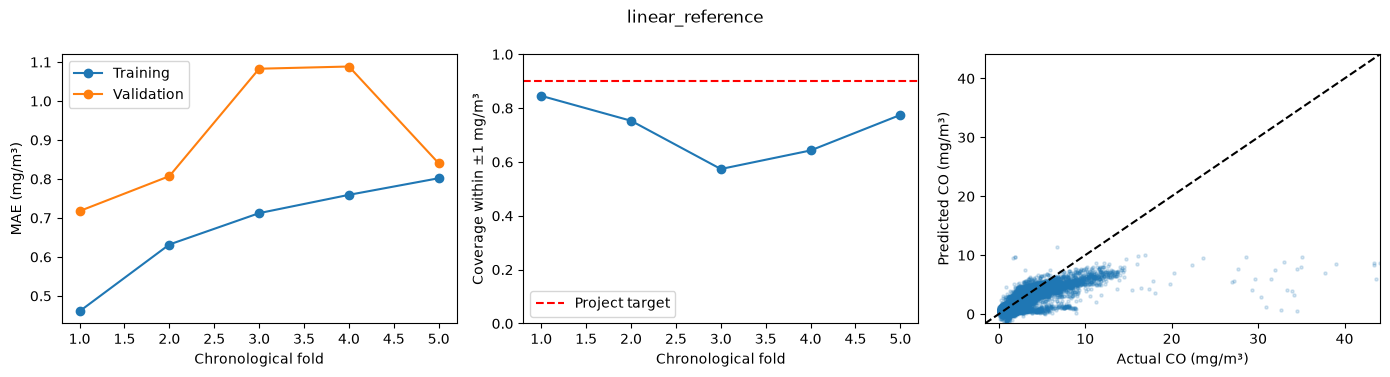

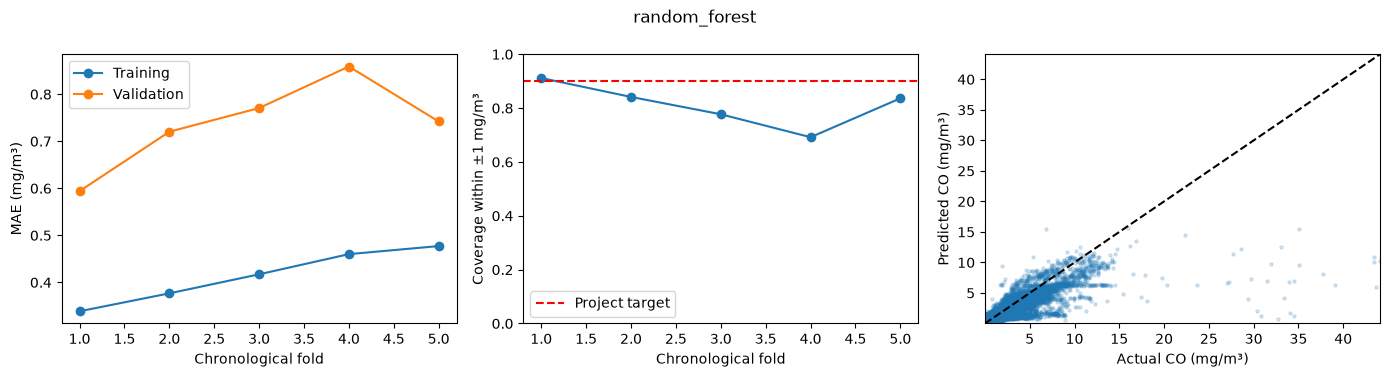

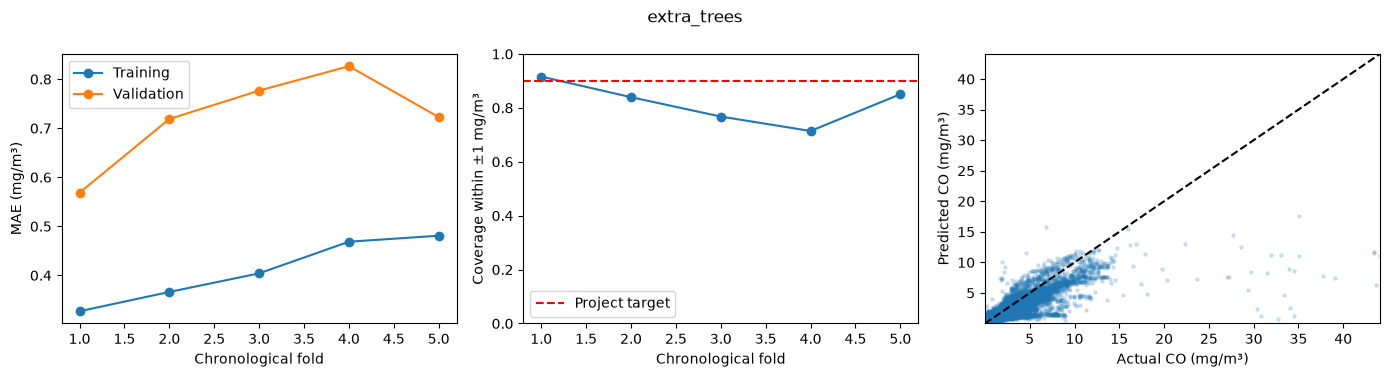

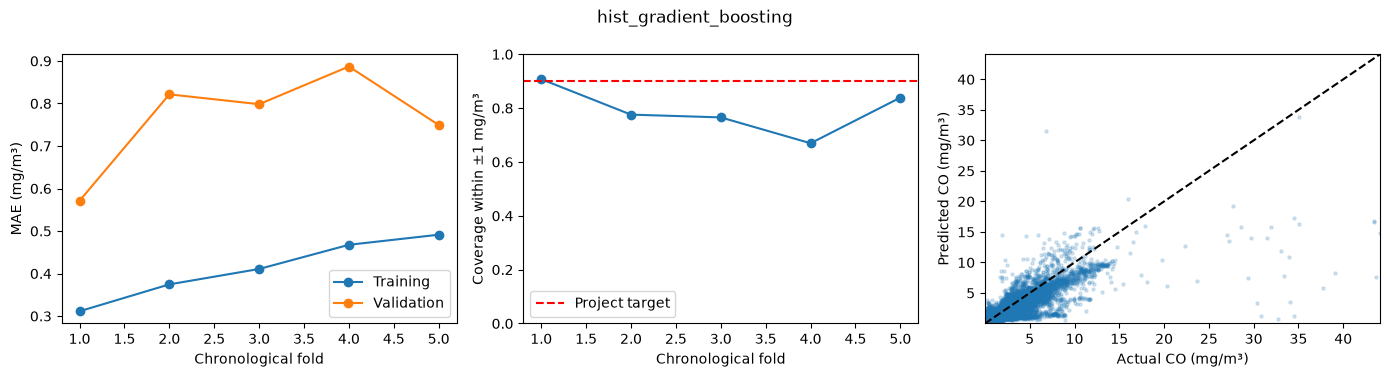

,model,group,rows,mae,coverage,mean_prediction_minus_actual
0,linear_reference,all_validation,18490,0.907319,0.718010,-0.601841
1,linear_reference,above_training_q75,7267,1.474214,0.491124,-1.121917
2,linear_reference,above_training_q95,2211,2.623523,0.260063,-2.596492
3,random_forest,all_validation,18490,0.737212,0.811790,-0.366580
4,random_forest,above_training_q75,7267,1.254633,0.586624,-0.967799
5,random_forest,above_training_q95,2211,2.289344,0.275893,-1.987201
6,extra_trees,all_validation,18490,0.722594,0.817631,-0.368496
7,extra_trees,above_training_q75,7267,1.245883,0.589927,-0.973863
8,extra_trees,above_training_q95,2211,2.267245,0.266848,-1.967220
9,hist_gradient_boosting,all_validation,18490,0.765503,0.791509,-0.343029


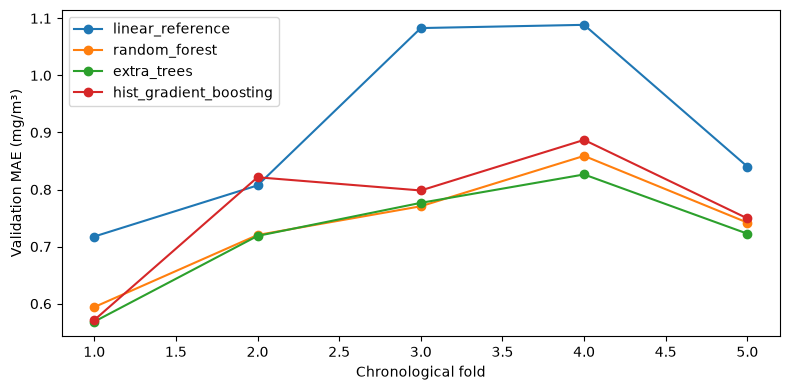

In [5]:
tail_tables=[]
for name in MODELS:
    fig = make_diagnostics(name, DETAILS[name], PREDICTIONS[name], FIGURES)
    display(fig)
    plt.close(fig)
    table=high_co_diagnostics(PREDICTIONS[name]);table.insert(0,"model",name)
    table.to_csv(RESULTS / name / "high_co_diagnostics.csv",index=False)
    tail_tables.append(table)
tail_comparison=pd.concat(tail_tables,ignore_index=True)
tail_comparison.to_csv(RESULTS / "high_co_comparison.csv",index=False)
display(tail_comparison)
fig, ax=plt.subplots(figsize=(8,4))
for name in MODELS:
    ax.plot(DETAILS[name].fold, DETAILS[name].validation_mae,"o-",label=name)
ax.set(xlabel="Chronological fold",ylabel="Validation MAE (mg/m³)")
ax.legend();fig.tight_layout();fig.savefig(FIGURES / "model_comparison.png",dpi=160)
plt.show()


All three nonlinear candidates improve the linear reference's validation MAE and coverage. Extra Trees has the smallest mean MAE and the highest coverage; HGB has the smallest mean RMSE. These differences do not establish statistical significance. Training MAE is lower than later validation MAE for each candidate. This is consistent with possible overfitting and temporal distribution change; the gap alone cannot distinguish them.

The actual-versus-predicted plots and negative high-CO mean signed errors demonstrate underprediction at higher concentrations. Diagnostic cutoffs are each training fold's 75th/95th target percentiles, then applied to validation rows; consequently the validation groups need not contain 25%/5% of rows. These are diagnostic thresholds, not legal limits or a deployable routing rule based on an unknown target. We do not use the unverified chat percentages as final evidence. Member 2 reported that high-CO weighting did not improve results, but no weighting implementation or result table was supplied; it is not a verified experiment here.

Potential causes include limited representation of extreme operating conditions, drift, missing explanatory measurements and tree averaging. The experiments establish the error pattern, not its physical cause. No extra model family, resampling, clipping or extreme-value correction is claimed to have run.

## 5. Model-owner interpretation and actual contributions

**Member 2 — Jiaqi Chen (Kiki), Random Forest.** Built on the common framework, reported multiple tuning rounds, supplied the latest numerical search and produced validation scatter analysis. Increasing the tree count gave diminishing reported improvements, so the final round fixed 600 trees. The validation gap and high-CO underprediction remain. Reported AI use: ChatGPT for coding and refining writing. See `notes/member2_submitted_analysis.md` for the attributed author text.

**Member 3 — Sirawich Anantapong (Poon), Extra Trees.** Supplied initial and latest searches, final code, plot and analysis. The latest depth-14 configuration gives a small improvement over depth 12; the gain is much smaller than variation across time folds. Depth 14 lies at the latest grid's upper boundary; larger depths were explored earlier under partly different combinations. Run 2 is member-reported without a separate numerical export. Reported AI use: Claude for understanding the framework/results, plotting and wording. See `notes/member3_submitted_analysis.md`.

**Member 4 — Hansini Devaraja, HGB.** Supplied the eight-configuration search, fold metrics, plots and analysis. Only the first validation fold exceeded the project coverage target. Fold-to-fold variation indicates limited temporal consistency. The integrated code replaces member-local Windows paths with project-relative paths and saves figures before packaging. Reported AI use: ChatGPT for understanding HGB, the framework and troubleshooting. See `notes/member4_submitted_analysis.md`.

**Member 1 — Wenyi.** Coordinated the common framework, data protocol, linear reference, receipt/review and integration. Codex assisted with implementation, execution, checks and explanations. Human review/adaptation must be recorded truthfully; AI-generated integration code is not attributed as unaided human implementation.

**Member 5 — Sauhandikaa.** Owns same-runtime cost review/measurement and the eventual locked final evaluation. These responsibilities are not evidence that the work is complete. Names/IDs and final contribution wording require member verification before submission.

## 6. Computational cost — Member 5 entry

Use `experiments/member5_benchmark.ipynb` to measure all four complete pipelines in one runtime. By default this master execution does not repeat expensive cost measurements. The function below is the exact same entry point.

Method: one fit warm-up followed by three measured full-development fits; report raw samples and median. A fitted pipeline predicts a fixed 1,000-row development batch (10 measurements after 3 warm-ups) and one fixed row (100 measurements after 5 warm-ups). Separate single-row latency, batch time and amortised per-row time. A separate fit samples incremental process RSS approximately every 5 ms; allocator reuse can hide memory peaks. Pickle size measures artifact size, not RAM. These local timings exclude sensor acquisition, network and serving overhead. Search time from different member machines is not a fair cost comparison.

In [6]:
RUN_COMMON_BENCHMARK = False
if RUN_COMMON_BENCHMARK:
    cost_table = benchmark_all(PROJECT / "results/costs", measured_by="Enter actual runner name before final reporting")
    display(cost_table)
elif (PROJECT / "results/costs/comparison.csv").exists():
    cost_table = pd.read_csv(PROJECT / "results/costs/comparison.csv")
    display(cost_table)
    print("Loaded recorded same-runtime cost evidence; no benchmark rerun in this execution. See its runtime.json.")
else:
    cost_table = None
    print("NOT RUN: common cost measurement. Open member5_benchmark.ipynb and enable its measurement cell.")


,model,protocol_id,runtime_id,fit_median_s,single_median_ms,single_p95_ms,batch_1000_median_ms,batch_amortised_us_per_row,fit_sampled_rss_increment_mib,serialized_pipeline_kib,train_rows,batch_rows,memory_method,final_test_run,measured_by
0,linear_reference,454f332babc7,faff91ccae8c,0.016342,1.024057,1.109194,1.103223,1.103223,0.000000,1.627930,22191,1000,"RSS increment, separate fit, ~5 ms sampling; a...",False,Codex integration reference; member 5 review p...
1,random_forest,454f332babc7,faff91ccae8c,23.822675,38.184981,41.241106,67.241904,67.241904,19.851562,24080.464844,22191,1000,"RSS increment, separate fit, ~5 ms sampling; a...",False,Codex integration reference; member 5 review p...
2,extra_trees,454f332babc7,faff91ccae8c,5.458572,26.663300,28.959927,56.463935,56.463935,40.988281,44718.245117,22191,1000,"RSS increment, separate fit, ~5 ms sampling; a...",False,Codex integration reference; member 5 review p...
3,hist_gradient_boosting,454f332babc7,faff91ccae8c,0.334465,2.548566,2.953513,8.384137,8.384137,0.000000,363.416016,22191,1000,"RSS increment, separate fit, ~5 ms sampling; a...",False,Codex integration reference; member 5 review p...


Loaded recorded same-runtime cost evidence; no benchmark rerun in this execution. See its runtime.json.


## 7. Development feasibility and remaining work

In [7]:
feasibility = comparison[["model","validation_mae","validation_rmse","validation_coverage"]].copy()
feasibility["coverage_target_met"] = feasibility.validation_coverage >= PROTOCOL["min_coverage"]
if cost_table is not None:
    feasibility=feasibility.merge(cost_table[["model","single_median_ms"]],on="model",validate="one_to_one")
    feasibility["latency_target_met"]=feasibility.single_median_ms<=PROTOCOL["max_median_single_ms"]
    feasibility["both_targets_met"]=feasibility.coverage_target_met & feasibility.latency_target_met
else:
    feasibility["latency_status"]="NOT RUN / awaiting common cost evidence"
feasibility.to_csv(RESULTS / "feasibility.csv",index=False)
display(feasibility)
status=pd.DataFrame([{"model":name,"validation_status":"RUN: selected settings, five development folds",
    "search_status":"Fixed OLS reference" if name=="linear_reference" else "Submitted latest search audited; rerun optional",
    "cost_status":"Recorded common-runtime evidence available" if cost_table is not None else "NOT RUN",
    "final_test_status":"SEALED / NOT RUN"} for name in MODELS])
status.to_csv(PROJECT / "results/experiment_status.csv",index=False)
display(status)


,model,validation_mae,validation_rmse,validation_coverage,coverage_target_met,single_median_ms,latency_target_met,both_targets_met
0,linear_reference,0.907319,1.689245,0.718010,False,1.024057,True,False
1,random_forest,0.737212,1.507902,0.811790,False,38.184981,False,False
2,extra_trees,0.722594,1.473532,0.817631,False,26.663300,False,False
3,hist_gradient_boosting,0.765503,1.465743,0.791509,False,2.548566,True,False


,model,validation_status,search_status,cost_status,final_test_status
0,linear_reference,"RUN: selected settings, five development folds",Fixed OLS reference,Recorded common-runtime evidence available,SEALED / NOT RUN
1,random_forest,"RUN: selected settings, five development folds",Submitted latest search audited; rerun optional,Recorded common-runtime evidence available,SEALED / NOT RUN
2,extra_trees,"RUN: selected settings, five development folds",Submitted latest search audited; rerun optional,Recorded common-runtime evidence available,SEALED / NOT RUN
3,hist_gradient_boosting,"RUN: selected settings, five development folds",Submitted latest search audited; rerun optional,Recorded common-runtime evidence available,SEALED / NOT RUN


None of the current candidates meets the 90% coverage target, regardless of latency. Extra Trees leads MAE/coverage in development but has not been selected as the final pipeline. Do not describe any candidate as deployable under both constraints. If the group recommends a best-available model for further investigation, distinguish that from a feasible deployed solution. Explain the engineering assumptions and seek course clarification if needed; do not retrospectively weaken thresholds to force a pass.

NOT RUN: gap sensitivity, alternative model families, nested chronological CV and training-size scalability experiments. These are possible extensions, not completed results. Full historical search reconstruction is also incomplete. Final report and slides will follow group agreement; they are not produced here.

## 8. Final model lock and held-out evaluation — SEALED / NOT RUN

This notebook deliberately contains no held-out prediction call. After comparing development performance and cost, the group must agree a final pipeline or document that no pipeline is feasible. Save a decision record with exact preprocessing, features, estimator parameters, data hash, protocol, approval and limitations before opening the reserved period.

The eventual final evaluator must train that single frozen pipeline on all development observations, make one held-out prediction vector, persist source-row IDs and the lock hash, compute the declared metrics and refuse repeat execution. A test failure must be reported; do not use it to retune or switch models. No final evaluator is enabled at this stage.

In [8]:
assert "X_test" not in globals() and "y_test" not in globals()
assert not (PROJECT / "results/final_test_metrics.json").exists()
assert len(SUMMARIES)==4 and all(s["protocol_id"]==PROTOCOL_ID for s in SUMMARIES)
assert all(len(PREDICTIONS[n])==18490 for n in MODELS)
assert np.isfinite(comparison[["train_mae","validation_mae","validation_rmse","validation_r2"]]).all().all()
write_json(RESULTS / "integration_verification.json", {
    "four_models_evaluated":True,"validation_predictions_per_model":18490,
    "preprocessing_audit_passed":True,"protocol_id":PROTOCOL_ID,
    "runtime_id":RUNTIME["runtime_id"],"final_test_run":False})
print("Integrated development checks passed. Final test remains sealed.")


Integrated development checks passed. Final test remains sealed.


## 9. AI disclosure and contribution approval

Codex/ChatGPT assisted Wenyi with interpreting the supplied brief/templates and CW1 work, designing and coding the common framework, reviewing returned files, integrating portable pipelines and regenerating validation results/diagnostics. The model owners reported the AI uses listed in Section 5. Actual numbers in this notebook come from executed code or explicitly identified submitted evidence; no final-test results are claimed.

The dated log is `notes/contributions_and_ai.md`. Original attachments are preserved locally under `.local_private/submissions/` with hashes in `notes/received_manifest.json`; they are excluded from Git. Public submitted numerical evidence is under `results/submitted/`. Final individual contribution wording and student IDs require the members' confirmation. Every member should be able to explain the entire experimental process during Q&A.